# CREDIT SCORING MODEL

**Objective:** Predict an individual's creditworthiness using past financial data.\
**Approach:** Use classification algorithms like Logistic Regression, Decision Trees, or Random Forest.

**Key Features:**

- Feature engineering from financial history.
- Model accuracy assessment using metrics like Precision, Recall, F1-Score, ROC-AUC.
- Dataset could include: income, debts, payment history, etc.

In [2]:
#Importing all libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


In [3]:
#initalizing
from sklearn.model_selection import train_test_split

In [4]:
#importing the dataset

df = pd.read_csv("cs-training.csv", index_col = 0)
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [5]:
#Checking out the dataset
df.shape

(150000, 11)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

**Checkinig for Missing values**

In [8]:
# Checking for missing values

df.isnull().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [9]:
df.loc[df["MonthlyIncome"].isnull() == True]

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
7,0,0.305682,57,0,5710.0,NaN,8,0,3,0,0.0
9,0,0.116951,27,0,46.0,NaN,2,0,0,0,NaN
17,0,0.061086,78,0,2058.0,NaN,10,0,2,0,0.0
33,0,0.083418,62,0,977.0,NaN,6,0,1,0,0.0
42,0,0.072898,81,0,75.0,NaN,7,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149977,0,0.000627,76,0,60.0,NaN,5,0,0,0,0.0
149978,0,0.236450,29,0,349.0,NaN,3,0,0,0,0.0
149985,0,0.037548,84,0,25.0,NaN,5,0,0,0,0.0
149993,0,0.871976,50,0,4132.0,NaN,11,0,1,0,3.0


**Checking for duplicates**

In [10]:
df.duplicated().sum()

np.int64(609)

In [11]:
df[df.duplicated(keep = False)].sort_values(list(df.columns))

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
134366,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
137103,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
25633,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
83553,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
139346,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
70203,1,1.0,55,0,0.0,1000.0,0,1,0,0,0.0
45369,1,1.0,55,98,0.0,NaN,0,98,0,98,0.0
115872,1,1.0,55,98,0.0,NaN,0,98,0,98,0.0
50784,1,1.0,57,0,0.0,NaN,0,0,0,0,0.0


In [12]:
df.columns

Index(['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='str')

**Checking for Unrealistic Figures**

**Age**

In [13]:
#Checking for unrealistic number in the age column
df.loc[df["age"] > 18].shape

(149999, 11)

**RevolvingUtilizationOfUnsecuredLines**

In [14]:
df[["RevolvingUtilizationOfUnsecuredLines"]].describe().T

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0


The RevolvingUtilizationOfUnsecuredLines should mostly fall between 0 and 1 but the max was 50,708  unit. 

**MonthlyIncome and DebtRatio**

In [15]:
#checking for unrealistc figure in the DebtRatio and the Monthly Income

df[["MonthlyIncome", "DebtRatio"]].describe().T

,count,mean,std,min,25%,50%,75%,max
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0


The value of the 50 % quatile for both the monthly income and the Debt Ratio appears to be thousand more than the max. Hence, the columns are flagged as suspicious of unrealistic figures

In [16]:
#Where does the number start jumping?

df[["MonthlyIncome", "DebtRatio"]].quantile([0.5, 0.9, 0.95, 0.99, 0.999, 0.9999, 1.0]).T

,0.5000,0.9000,0.9500,0.9900,0.9990,0.9999,1.0000
MonthlyIncome,5400.000000,11666.0,14587.6,25000.00,78395.748,439685.1000,3008750.0
DebtRatio,0.366508,1267.0,2449.0,4979.04,10613.074,40362.0023,329664.0


The Number starts to jump from the 99% quatile for the Monthly income and from the 90 % for the DebtRatio

In [17]:
#Looking at the biggest rows in the Monthly column
df.nlargest(10, "MonthlyIncome")


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
73764,0,0.007328,52,0,0.001470,3008750.0,10,0,1,0,3.0
137141,0,0.000000,68,0,0.002776,1794060.0,15,0,1,0,0.0
111366,0,0.163856,44,0,0.004013,1560100.0,12,0,4,0,2.0
50641,0,0.469025,44,1,0.004537,1072500.0,9,0,2,0,1.0
122544,0,0.041599,55,0,0.000147,835040.0,8,0,0,0,0.0
123292,0,0.226333,67,1,0.005570,730483.0,23,0,1,0,0.0
93565,0,0.071628,50,0,0.008268,702500.0,12,0,4,0,2.0
96550,0,0.064155,52,0,0.003698,699530.0,11,0,2,0,1.0
119137,0,0.151329,49,0,0.001313,649587.0,8,0,0,1,3.0
37079,0,0.000000,83,0,0.000000,629000.0,3,0,0,0,0.0


In [18]:
#Looking at the biggest rows in the DebtRatio column
df.nlargest(10, "DebtRatio")

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
60153,0,0.000000,65,0,329664.0,NaN,9,0,3,0,0.0
36601,0,0.001782,65,0,326442.0,NaN,6,0,1,0,0.0
127048,0,0.034290,58,1,307001.0,NaN,16,0,4,0,2.0
58901,0,0.182640,37,0,220516.0,NaN,8,0,3,0,NaN
4855,0,0.000000,56,0,168835.0,NaN,10,0,3,0,2.0
7514,0,0.152293,71,0,110952.0,NaN,9,0,0,0,0.0
103042,0,0.364845,65,0,106885.0,NaN,8,0,4,0,NaN
69846,0,0.386451,66,0,101320.0,NaN,12,0,0,0,0.0
66786,0,1.000000,63,0,61907.0,NaN,13,0,6,0,0.0
53683,0,1.000000,89,0,61106.5,1.0,2,0,0,0,0.0


In [19]:
# Counting how many are suspicious in the debt column

for t in [1, 10, 100, 1000]:
    n = (df["DebtRatio"] > t).sum()
    print("DebtRatio above", t, ":", n, "rows")

DebtRatio above 1 : 35137 rows
DebtRatio above 10 : 28877 rows
DebtRatio above 100 : 24380 rows
DebtRatio above 1000 : 16892 rows


In [20]:
# Counting how many are suspicious in the Monthly Income column

for t in [20000, 50000, 100000]:
    n = (df["MonthlyIncome"] > t).sum()
    print("MonthlyIncome above", t, ":", n, "rows")

MonthlyIncome above 20000 : 2103 rows
MonthlyIncome above 50000 : 301 rows
MonthlyIncome above 100000 : 70 rows


Diagnosing the Debt Ratio:

In [21]:
# Are the giant debt ratios linked to blank income

big = df["DebtRatio"] > 100
print(big.sum())
print(df.loc[big, "MonthlyIncome"].isnull().mean())

24380
0.9308039376538146


It is observed that the Giant Debt Ratio is linked to blank Income, Those with extremely high DebtRatio is 90 % having missing Income

Diagnosing the Monthly Income:

In [22]:
# Checking people with the biggest incomes
df.nlargest(10, "MonthlyIncome")


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
73764,0,0.007328,52,0,0.001470,3008750.0,10,0,1,0,3.0
137141,0,0.000000,68,0,0.002776,1794060.0,15,0,1,0,0.0
111366,0,0.163856,44,0,0.004013,1560100.0,12,0,4,0,2.0
50641,0,0.469025,44,1,0.004537,1072500.0,9,0,2,0,1.0
122544,0,0.041599,55,0,0.000147,835040.0,8,0,0,0,0.0
123292,0,0.226333,67,1,0.005570,730483.0,23,0,1,0,0.0
93565,0,0.071628,50,0,0.008268,702500.0,12,0,4,0,2.0
96550,0,0.064155,52,0,0.003698,699530.0,11,0,2,0,1.0
119137,0,0.151329,49,0,0.001313,649587.0,8,0,0,1,3.0
37079,0,0.000000,83,0,0.000000,629000.0,3,0,0,0,0.0


The income is unusuall but realistic, Hence checking the full records of the top 10 records with high income shows that the records with the high income are realist, from the age to the debt ratio to the number of dependent

**Observed Problems**

- Missing values in the 'MonthlyIncome' column = 29731
- Missing values in the 'NumberOfDependents' column = 3924
- Duplicates in rows = 960
- Impossible value in the Age column (One row is observed to be having an Age record of 0)
- Impossible value in the RevolvingUtilizationOfUnsecuredLines column
- There is impossible figure at the DebtRatio


### Cleaning 1

**Fixing problems:** One that is not needed for the learning 
- Removing duplicates
- Fixing wrong type
- Handling impossible values

(cleaning the whole set)


**Handling Duplicated Rows**

There is no Primary key or unique ID in the dataset, hence duplicated column would be handled by observing and dropping every rows with a duplicated in decimal or float figures

In [23]:
df[df.duplicated(keep = False)].sort_values(list(df.columns)).describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,960.0,0.033333,0.179599,0.0,0.0,0.0,0.0,1.0
RevolvingUtilizationOfUnsecuredLines,960.0,0.481250,0.499909,0.0,0.0,0.0,1.0,1.0
age,960.0,50.662500,23.182700,21.0,25.0,53.0,71.0,99.0
NumberOfTime30-59DaysPastDueNotWorse,960.0,6.839583,24.982983,0.0,0.0,0.0,0.0,98.0
DebtRatio,960.0,1.753021,29.071629,0.0,0.0,0.0,0.0,520.0
MonthlyIncome,148.0,763.837838,730.642500,0.0,1.0,820.0,929.0,3500.0
NumberOfOpenCreditLinesAndLoans,960.0,1.615625,1.620761,0.0,0.0,1.0,2.0,10.0
NumberOfTimes90DaysLate,960.0,6.859375,24.977947,0.0,0.0,0.0,0.0,98.0
NumberRealEstateLoansOrLines,960.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
NumberOfTime60-89DaysPastDueNotWorse,960.0,6.839583,24.982983,0.0,0.0,0.0,0.0,98.0


In [24]:
#defining the rule to handle duplicates
decimal_col = ["DebtRatio", "RevolvingUtilizationOfUnsecuredLines"]

has_decimal = (df[decimal_col] % 1 != 0).any(axis=1)
is_repeat = df.duplicated(keep = "first")

df = df[~(has_decimal & is_repeat)] # updating the dataset with the rule
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [25]:
df.duplicated().sum()

np.int64(307)

In [26]:
rest = df[df.duplicated(keep=False)]
rest.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,495.0,0.000000,0.000000,0.0,0.00,0.0,0.0,0.0
RevolvingUtilizationOfUnsecuredLines,495.0,0.000000,0.000000,0.0,0.00,0.0,0.0,0.0
age,495.0,60.246465,22.359681,21.0,46.00,65.0,79.0,99.0
NumberOfTime30-59DaysPastDueNotWorse,495.0,0.000000,0.000000,0.0,0.00,0.0,0.0,0.0
DebtRatio,495.0,3.169697,40.399016,0.0,0.00,0.0,0.0,520.0
MonthlyIncome,64.0,890.734375,811.678747,0.0,615.25,820.0,929.0,3500.0
NumberOfOpenCreditLinesAndLoans,495.0,2.642424,1.560980,1.0,1.00,2.0,3.0,10.0
NumberOfTimes90DaysLate,495.0,0.000000,0.000000,0.0,0.00,0.0,0.0,0.0
NumberRealEstateLoansOrLines,495.0,0.000000,0.000000,0.0,0.00,0.0,0.0,0.0
NumberOfTime60-89DaysPastDueNotWorse,495.0,0.000000,0.000000,0.0,0.00,0.0,0.0,0.0


609 exact duplicate rows was found. I removed 302 that had decimal values in the ratio ccolumns, since two people matching exactly is very unlikely. I kept the remaining 307 plain duplicates, since they could be different people

**Handling Impossible Values**

Impossible values observed in the age and the DebtRatio column

**Handling Impossible Values in the age column**

In [27]:
# Handling Impossible value in the age column
df[df["age"] < 18]

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
65696,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0


In [28]:
df = df[~(df["age"] < 18)]
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


In [29]:
df[df["age"] < 18]

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents


One impossible value observed and dropped in the age column

**Handling Impossible Values in the RevolvingUtilizationOfUnsecuredLines Column**

Creating a new column and flagging the impossible or suspicious values in the column (rule: if the RevolvingUtilizationOfUnsecuredLines is greater than a specific quantile of the entire column, It would be flagged and the values would be rounded down to the 99.9th percentile)

In [30]:
# Checking out the quantile from 90 percent to 99.9 percent
df["RevolvingUtilizationOfUnsecuredLines"].quantile([0.9, 0.95, 0.99, 0.995, 0.999]).T

0.900       0.977517
0.950       1.000000
0.990       1.093399
0.995       1.368221
0.999    1572.824000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

In [31]:
#using the 0.995 quantile as the cap/base for validation
cap = df["RevolvingUtilizationOfUnsecuredLines"].quantile(0.995)
cap
df["RevolvingUtilizationOfUnsecuredLines_Flagged"] = (df["RevolvingUtilizationOfUnsecuredLines"] > cap).astype(int)
df["RevolvingUtilizationOfUnsecuredLines"] = df["RevolvingUtilizationOfUnsecuredLines"].clip(upper =  cap)

In [32]:
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,RevolvingUtilizationOfUnsecuredLines_Flagged
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0,0
149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0,0
149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0,0
149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0,0


**Handling Impossible Values in the Debt Ratio column**

Creating a new column and flagging the impossible values in the column (Rule: If the Debt Ratio is greater than 4 unit, It would be flagged and the values would be rounded down to 4)

In [33]:
(df["DebtRatio"] > 4).sum()

np.int64(29888)

In [34]:
#Using the rule: If DebtRatio is greater than 100, It would be flagged (1) and if not, it would not be flagged (0)

df["DebtRatio_Flagged"] = (df["DebtRatio"] > 4).astype(int)
df["DebtRatio"] = df["DebtRatio"].clip(upper = 4)

In [35]:
df

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,RevolvingUtilizationOfUnsecuredLines_Flagged,DebtRatio_Flagged
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,0,0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0,0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,0,0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0,0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0,0,0
149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0,0,0
149998,0,0.246044,58,0,4.000000,NaN,18,0,1,0,0.0,0,1
149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0,0,0


### SPLITTING THE DATASET

Splitting the dataset into training and testing set, with a testing set of 20 percent

In [36]:
#Seperating the feature (X) from the target (y)

X = df.drop("SeriousDlqin2yrs", axis = 1)
y = df["SeriousDlqin2yrs"]


In [37]:
#Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 40,
    stratify = y
)

In [38]:
X_train.shape

(119757, 12)

In [39]:
X_test.shape

(29940, 12)

### Cleaning 2

Fixing Problems on the testing set: 
- Distribution Analysis
- Missing value handling



**Training Data Distribution Analysis**

1. Class Distribution
- Examine the distribution of the target variable  (y_train)
- Determine the proportion of each class (0 and 1)
- Identify class imbalance and consider appropriate handling techinques if necessary

2. Outlier Detection
- Examin numerical features in X_train for unusually high or low values
- Use boxplots and the interquartile range (IQR) method to identify potential outliers
- Investigate identified outliers before deciding whether to retain, transform, or remove them

In [40]:
#Examining the distribution of the target variable (y_train)

print(y_train.value_counts(normalize = True) * 100)

SeriousDlqin2yrs
0    93.313961
1     6.686039
Name: proportion, dtype: float64


- 0 = 93.313961
- 1 = 6.686039

This indicates that the training dataset is imbalanced, with class 0 being the majourity class and class 1 being the minority class.

Would use the model parameter to handle the imbalance

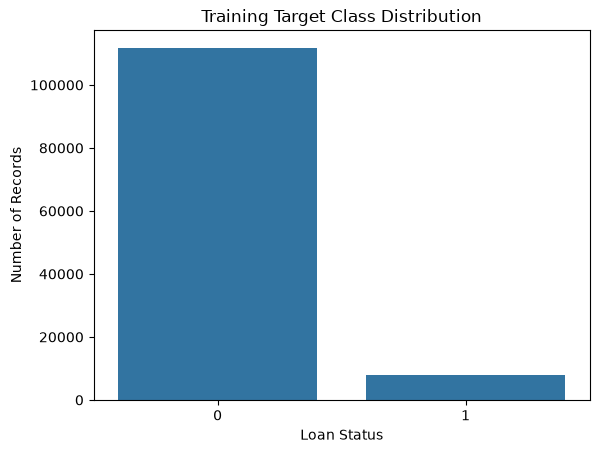

In [41]:
#Visualizing the distribution

sns.countplot(x = y_train)
plt.title("Training Target Class Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Records")

plt.show()

In [42]:
#Outlier Detection

#using a boxplot

numerical_cols = X_train.select_dtypes(include = "number").columns
print(numerical_cols)

Index(['RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents', 'RevolvingUtilizationOfUnsecuredLines_Flagged',
       'DebtRatio_Flagged'],
      dtype='str')


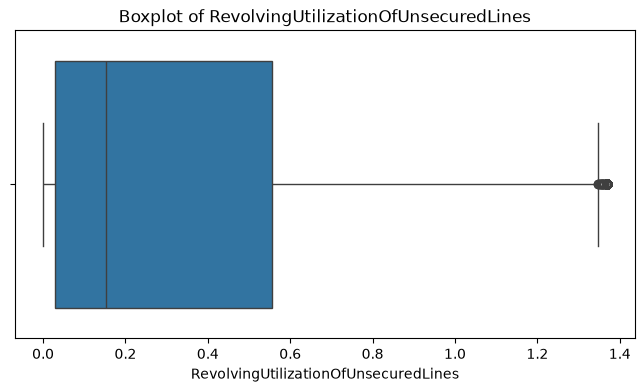

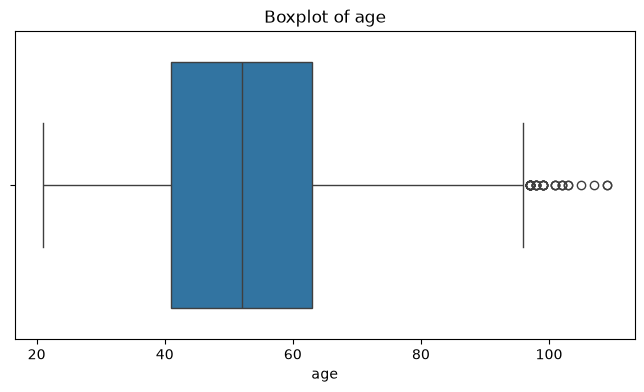

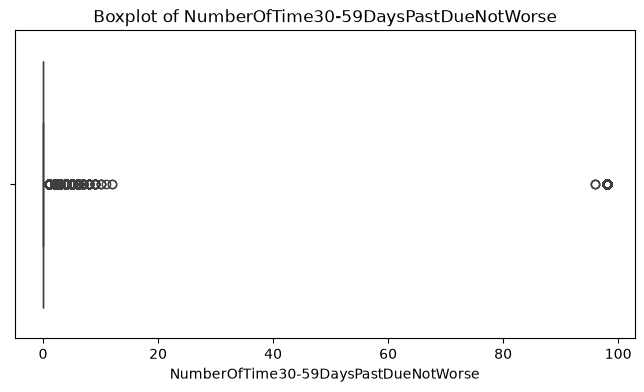

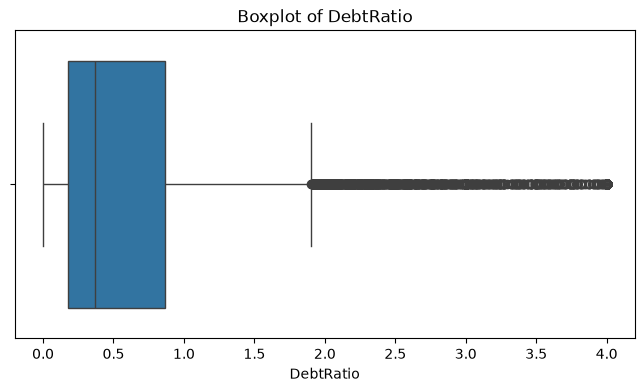

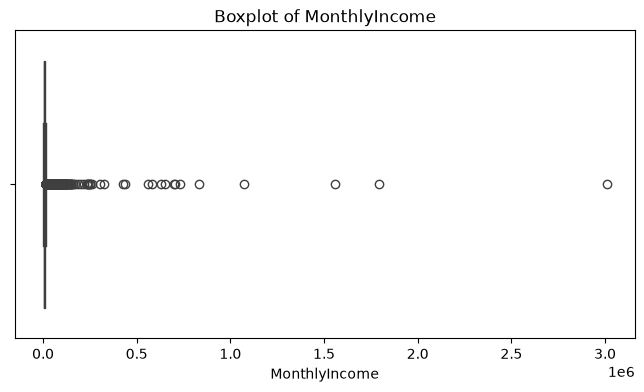

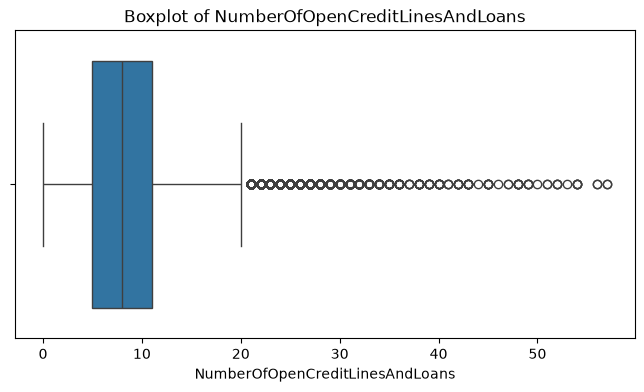

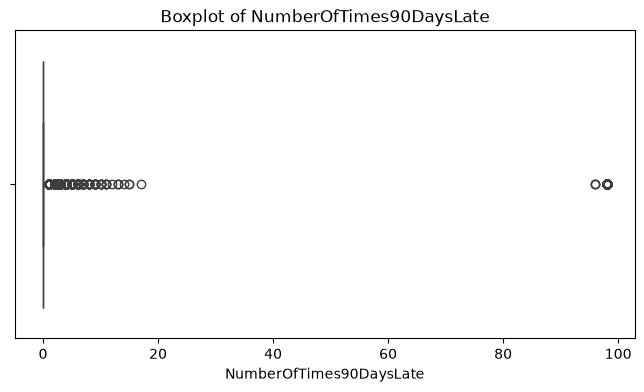

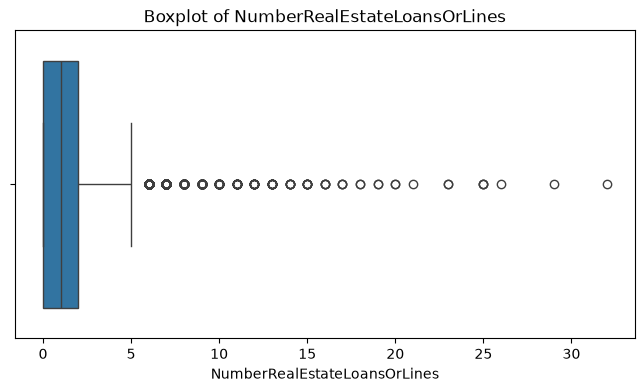

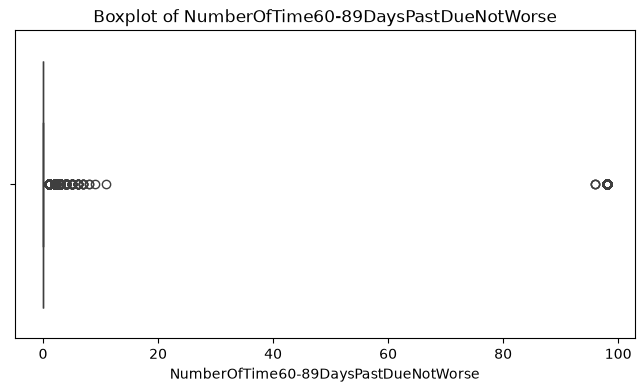

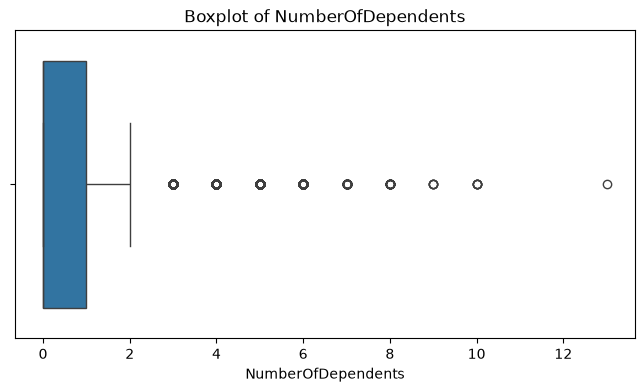

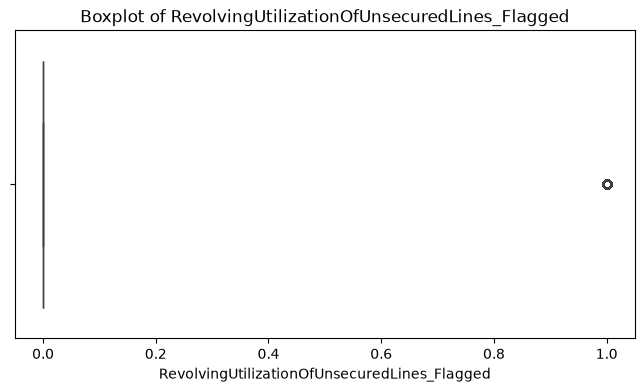

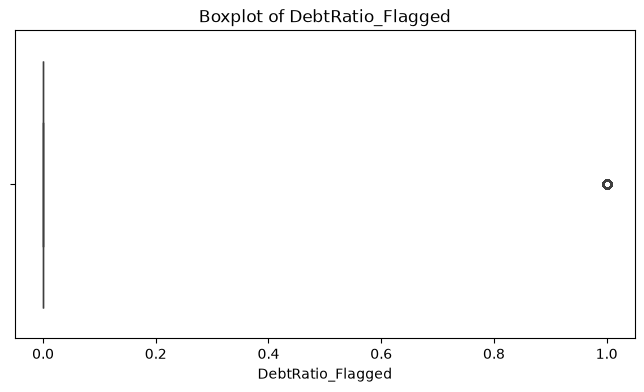

In [43]:
for col in numerical_cols:
    plt.figure(figsize = (8, 4))

    sns.boxplot(x = X_train[col])

    plt.title(f"Boxplot of {col}")

    plt.show()

In [44]:
#Checking the skewness of the numerical features
X_train[numerical_cols].skew().sort_values(ascending = False)

MonthlyIncome                                   108.990996
NumberOfTime60-89DaysPastDueNotWorse             25.593832
NumberOfTimes90DaysLate                          25.280229
NumberOfTime30-59DaysPastDueNotWorse             24.629199
RevolvingUtilizationOfUnsecuredLines_Flagged     14.141709
NumberRealEstateLoansOrLines                      3.030237
NumberOfDependents                                1.558550
DebtRatio_Flagged                                 1.506650
DebtRatio                                         1.358814
NumberOfOpenCreditLinesAndLoans                   1.227190
RevolvingUtilizationOfUnsecuredLines              0.954899
age                                               0.191754
dtype: float64

In [45]:
#Checking the descriptive statistics
X_train[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,119757.0,0.321269,0.355596,0.0,0.029851,0.153960,0.556592,1.368221e+00
age,119757.0,52.311472,14.732589,21.0,41.000000,52.000000,63.000000,1.090000e+02
NumberOfTime30-59DaysPastDueNotWorse,119757.0,0.390775,3.828523,0.0,0.000000,0.000000,0.000000,9.800000e+01
DebtRatio,119757.0,1.088167,1.493928,0.0,0.176308,0.366606,0.867267,4.000000e+00
MonthlyIncome,96206.0,6701.536152,15714.345020,0.0,3400.000000,5400.000000,8250.000000,3.008750e+06
NumberOfOpenCreditLinesAndLoans,119757.0,8.466186,5.135346,0.0,5.000000,8.000000,11.000000,5.700000e+01
NumberOfTimes90DaysLate,119757.0,0.235585,3.801140,0.0,0.000000,0.000000,0.000000,9.800000e+01
NumberRealEstateLoansOrLines,119757.0,1.020057,1.126008,0.0,0.000000,1.000000,2.000000,3.200000e+01
NumberOfTime60-89DaysPastDueNotWorse,119757.0,0.210226,3.785885,0.0,0.000000,0.000000,0.000000,9.800000e+01
NumberOfDependents,116676.0,0.759436,1.114802,0.0,0.000000,0.000000,1.000000,1.300000e+01


In [46]:
#Checking out outlier using the IQR (Interquatile Rule)

quantile1 = X_train[numerical_cols].quantile(0.25)
quantile3 = X_train[numerical_cols].quantile(0.75)

iqr = quantile3-quantile1
iqr

RevolvingUtilizationOfUnsecuredLines               0.526741
age                                               22.000000
NumberOfTime30-59DaysPastDueNotWorse               0.000000
DebtRatio                                          0.690959
MonthlyIncome                                   4850.000000
NumberOfOpenCreditLinesAndLoans                    6.000000
NumberOfTimes90DaysLate                            0.000000
NumberRealEstateLoansOrLines                       2.000000
NumberOfTime60-89DaysPastDueNotWorse               0.000000
NumberOfDependents                                 1.000000
RevolvingUtilizationOfUnsecuredLines_Flagged       0.000000
DebtRatio_Flagged                                  0.000000
dtype: float64

In [47]:
low = quantile1 - ( 1.5* iqr)
high = quantile1 + ( 1.5 * iqr)


#Number of values outside the high and low/ outside the IQR
n_out = ((X_train[numerical_cols] < low) | (X_train[numerical_cols] > high)).sum()
n_out

RevolvingUtilizationOfUnsecuredLines            19092
age                                              9044
NumberOfTime30-59DaysPastDueNotWorse            19109
DebtRatio                                       26588
MonthlyIncome                                   12139
NumberOfOpenCreditLinesAndLoans                 13949
NumberOfTimes90DaysLate                          6644
NumberRealEstateLoansOrLines                     2894
NumberOfTime60-89DaysPastDueNotWorse             6042
NumberOfDependents                              26327
RevolvingUtilizationOfUnsecuredLines_Flagged      590
DebtRatio_Flagged                               23850
dtype: int64

**Handling Missing Values**

In [48]:
missing_values = X_train[numerical_cols].isnull().sum()
missing_values

RevolvingUtilizationOfUnsecuredLines                0
age                                                 0
NumberOfTime30-59DaysPastDueNotWorse                0
DebtRatio                                           0
MonthlyIncome                                   23551
NumberOfOpenCreditLinesAndLoans                     0
NumberOfTimes90DaysLate                             0
NumberRealEstateLoansOrLines                        0
NumberOfTime60-89DaysPastDueNotWorse                0
NumberOfDependents                               3081
RevolvingUtilizationOfUnsecuredLines_Flagged        0
DebtRatio_Flagged                                   0
dtype: int64

Handling missing values in the MonthlyIncome

In [49]:
#Flagging the Income Missing (1, missing) (0, not missing) and filling the missing values with the median of the column
#Flagging the training set

X_train["IncomeMissing"] = X_train["MonthlyIncome"].isnull().astype(int)
X_train["IncomeMissing"]

68020     0
55223     0
116777    0
134150    0
92804     0
         ..
78899     0
110200    1
44514     1
7461      0
43298     0
Name: IncomeMissing, Length: 119757, dtype: int64

In [50]:
#Flagging the testing set

X_test["IncomeMissing"] = X_test["MonthlyIncome"].isnull().astype(int)
X_test["IncomeMissing"]

132203    0
105012    0
129842    0
137249    1
122638    0
         ..
97606     0
94508     0
88344     1
119338    0
72543     0
Name: IncomeMissing, Length: 29940, dtype: int64

In [51]:
#Filling the training set with the median
fill = X_train["MonthlyIncome"].median()
print(f"Fill value: {fill}")

X_train["MonthlyIncome"] = X_train["MonthlyIncome"].fillna(fill)

Fill value: 5400.0


In [52]:
#Filling the testing set with the median

X_test["MonthlyIncome"] = X_test["MonthlyIncome"].fillna(fill)

Handling missing values in the NumberOfDependents

In [53]:
#Flagging the NumberOfDependents (1, missing) (0, not missing) and filling the missing values with the median of the column
#Flagging the training set

X_train["NumberOfDependents_Missing"] = X_train["NumberOfDependents"].isnull().astype(int)
X_train["NumberOfDependents_Missing"]

68020     0
55223     0
116777    0
134150    0
92804     0
         ..
78899     0
110200    0
44514     0
7461      0
43298     0
Name: NumberOfDependents_Missing, Length: 119757, dtype: int64

In [54]:
#Flagging the testing set

X_test["NumberOfDependents_Missing"] = X_test["NumberOfDependents"].isnull().astype(int)
X_test["NumberOfDependents_Missing"]

132203    0
105012    0
129842    0
137249    0
122638    0
         ..
97606     0
94508     0
88344     0
119338    0
72543     0
Name: NumberOfDependents_Missing, Length: 29940, dtype: int64

In [55]:
#Filling the training set with the median
fill = X_train["NumberOfDependents"].median()
print(f"Fill value: {fill}")

X_train["NumberOfDependents"] = X_train["NumberOfDependents"].fillna(fill)

Fill value: 0.0


In [56]:
#Filling the testing set with the median
X_test["NumberOfDependents"] = X_test["NumberOfDependents"].fillna(fill)

In [57]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,119757.0,0.321269,0.355596,0.0,0.029851,0.153960,0.556592,1.368221e+00
age,119757.0,52.311472,14.732589,21.0,41.000000,52.000000,63.000000,1.090000e+02
NumberOfTime30-59DaysPastDueNotWorse,119757.0,0.390775,3.828523,0.0,0.000000,0.000000,0.000000,9.800000e+01
DebtRatio,119757.0,1.088167,1.493928,0.0,0.176308,0.366606,0.867267,4.000000e+00
MonthlyIncome,119757.0,6445.580526,14094.160527,0.0,3900.000000,5400.000000,7400.000000,3.008750e+06
NumberOfOpenCreditLinesAndLoans,119757.0,8.466186,5.135346,0.0,5.000000,8.000000,11.000000,5.700000e+01
NumberOfTimes90DaysLate,119757.0,0.235585,3.801140,0.0,0.000000,0.000000,0.000000,9.800000e+01
NumberRealEstateLoansOrLines,119757.0,1.020057,1.126008,0.0,0.000000,1.000000,2.000000,3.200000e+01
NumberOfTime60-89DaysPastDueNotWorse,119757.0,0.210226,3.785885,0.0,0.000000,0.000000,0.000000,9.800000e+01
NumberOfDependents,119757.0,0.739898,1.106918,0.0,0.000000,0.000000,1.000000,1.300000e+01


### EXPLORATORY DATA ANALYSIS (EDA)

**Setup**

In [58]:
train = X_train.copy()
train["Target"] = y_train
train


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,RevolvingUtilizationOfUnsecuredLines_Flagged,DebtRatio_Flagged,IncomeMissing,NumberOfDependents_Missing,Target
68020,0.861419,61,2,0.566166,12513.0,16,0,2,0,1.0,0,0,0,0,1
55223,0.966407,45,0,0.065950,3350.0,4,0,0,0,1.0,0,0,0,0,0
116777,0.907869,49,0,0.339884,11600.0,8,0,2,0,1.0,0,0,0,0,0
134150,0.062956,52,0,0.203208,9600.0,10,0,1,0,0.0,0,0,0,0,0
92804,0.248904,62,0,0.420186,8500.0,19,0,2,0,0.0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78899,0.003785,76,0,0.002204,8167.0,19,0,0,0,1.0,0,0,0,0,0
110200,0.203918,65,0,4.000000,5400.0,5,0,0,0,0.0,0,1,1,0,0
44514,0.010227,49,0,4.000000,5400.0,11,0,2,0,3.0,0,1,1,0,0
7461,0.169903,60,0,0.640853,10833.0,15,0,3,0,5.0,0,0,0,0,0


In [59]:
# Quick snapshot

train.shape


(119757, 15)

In [60]:
#checking the proportion of the Target
train["Target"].value_counts(normalize = True)

Target
0    0.93314
1    0.06686
Name: proportion, dtype: float64

In [61]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,119757.0,0.321269,0.355596,0.0,0.029851,0.153960,0.556592,1.368221e+00
age,119757.0,52.311472,14.732589,21.0,41.000000,52.000000,63.000000,1.090000e+02
NumberOfTime30-59DaysPastDueNotWorse,119757.0,0.390775,3.828523,0.0,0.000000,0.000000,0.000000,9.800000e+01
DebtRatio,119757.0,1.088167,1.493928,0.0,0.176308,0.366606,0.867267,4.000000e+00
MonthlyIncome,119757.0,6445.580526,14094.160527,0.0,3900.000000,5400.000000,7400.000000,3.008750e+06
NumberOfOpenCreditLinesAndLoans,119757.0,8.466186,5.135346,0.0,5.000000,8.000000,11.000000,5.700000e+01
NumberOfTimes90DaysLate,119757.0,0.235585,3.801140,0.0,0.000000,0.000000,0.000000,9.800000e+01
NumberRealEstateLoansOrLines,119757.0,1.020057,1.126008,0.0,0.000000,1.000000,2.000000,3.200000e+01
NumberOfTime60-89DaysPastDueNotWorse,119757.0,0.210226,3.785885,0.0,0.000000,0.000000,0.000000,9.800000e+01
NumberOfDependents,119757.0,0.739898,1.106918,0.0,0.000000,0.000000,1.000000,1.300000e+01


<function matplotlib.pyplot.show(close=None, block=None)>

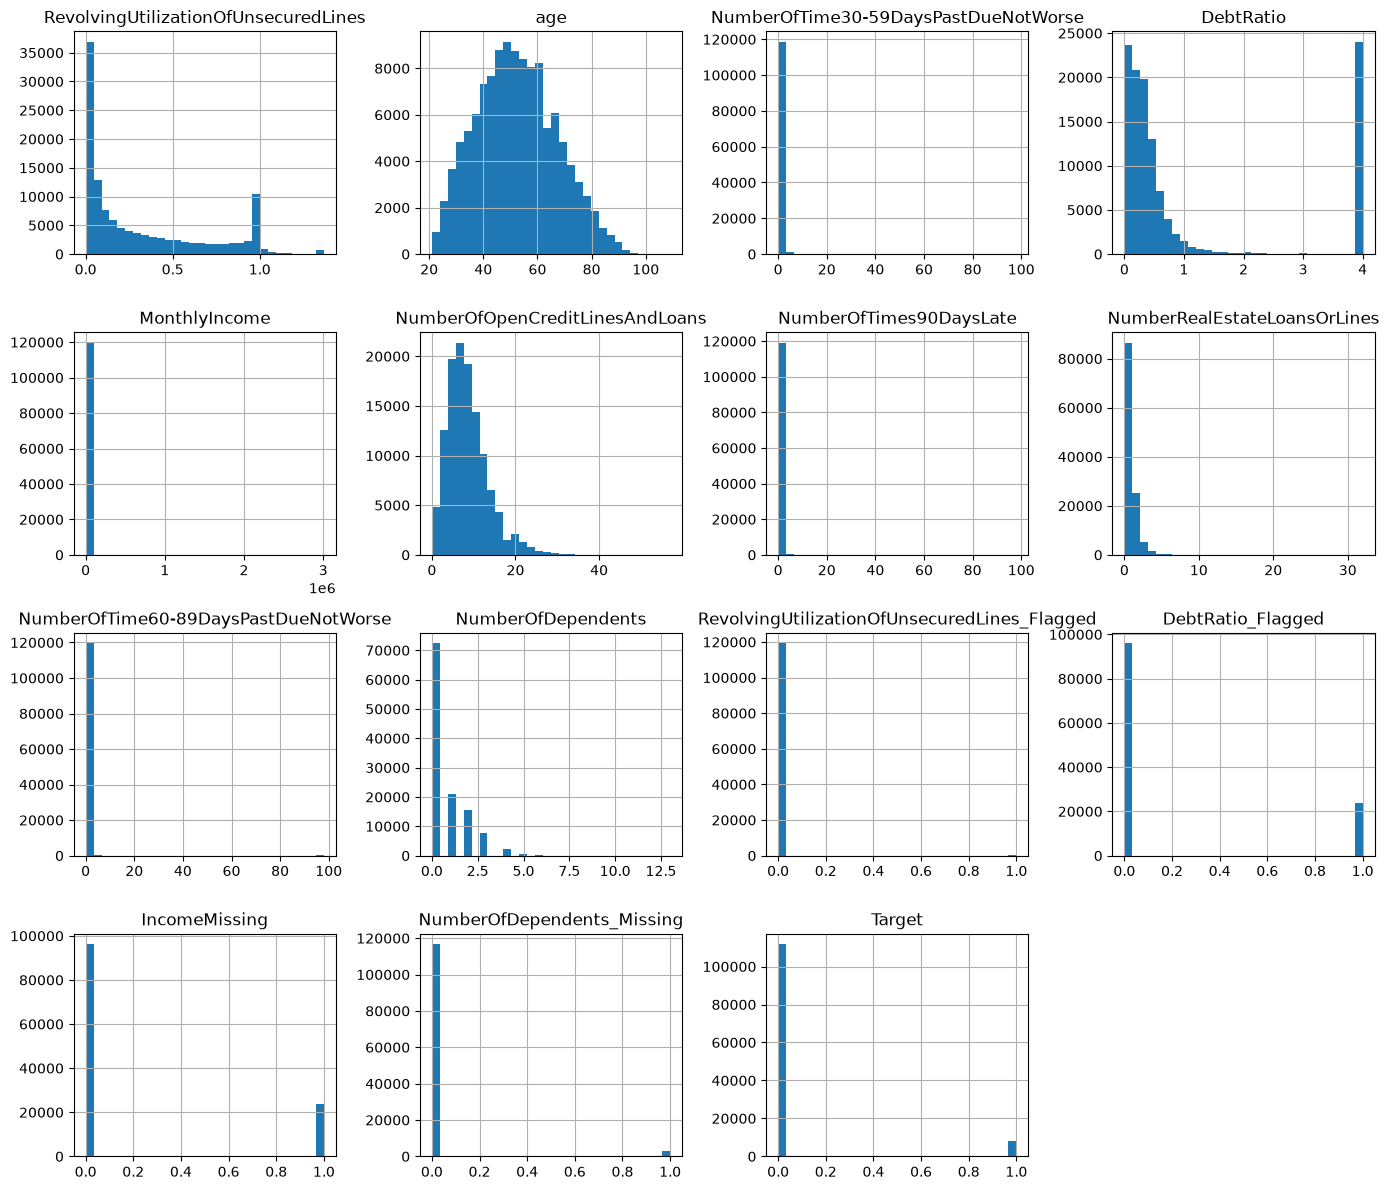

In [62]:
# One column at a time
train.hist(figsize = (14, 12), bins = 30)
plt.tight_layout()
plt.show

In [63]:
train.skew(numeric_only = True).sort_values()

age                                               0.191754
RevolvingUtilizationOfUnsecuredLines              0.954899
NumberOfOpenCreditLinesAndLoans                   1.227190
DebtRatio                                         1.358814
DebtRatio_Flagged                                 1.506650
IncomeMissing                                     1.526389
NumberOfDependents                                1.595782
NumberRealEstateLoansOrLines                      3.030237
Target                                            3.468211
NumberOfDependents_Missing                        5.991396
RevolvingUtilizationOfUnsecuredLines_Flagged     14.141709
NumberOfTime30-59DaysPastDueNotWorse             24.629199
NumberOfTimes90DaysLate                          25.280229
NumberOfTime60-89DaysPastDueNotWorse             25.593832
MonthlyIncome                                   121.410100
dtype: float64

**Each Column by the Target**

In [64]:
# Each column by the target
train.groupby("Target").median()

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,RevolvingUtilizationOfUnsecuredLines_Flagged,DebtRatio_Flagged,IncomeMissing,NumberOfDependents_Missing
Target,,,,,,,,,,,,,,
0,0.133166,52.0,0.0,0.362999,5400.0,8.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.837432,46.0,0.0,0.427056,5250.0,7.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [65]:
train.groupby("Target").mean()

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,RevolvingUtilizationOfUnsecuredLines_Flagged,DebtRatio_Flagged,IncomeMissing,NumberOfDependents_Missing
Target,,,,,,,,,,,,,,
0,0.294081,52.766685,0.256841,1.092080,6506.236036,8.509843,0.111911,1.023123,0.103875,0.726309,0.003624,0.201414,0.198747,0.026309
1,0.700713,45.958286,2.260022,1.033551,5599.039590,7.856875,1.961659,0.977270,1.694517,0.929562,0.023105,0.167603,0.167478,0.017610


**Bad Borrower by Group**

In [66]:
#Bad borrower rate by age group 
train.groupby(pd.qcut(train["age"], 5), observed = True)["Target"].agg(["mean", "size"]) 

,mean,size
age,,
"(20.999, 39.0]",0.105422,25450
"(39.0, 48.0]",0.083974,24448
"(48.0, 56.0]",0.071379,23228
"(56.0, 65.0]",0.044680,23769
"(65.0, 109.0]",0.024101,22862


Default rate decreases steadily as age increases, so age is a useful predictor.

In [67]:
#Bad borrower rate by RevolvingUtilizationOfUnsecuredLines group 
train.groupby(pd.qcut(train["RevolvingUtilizationOfUnsecuredLines"], 5), observed = True)["Target"].agg(["mean", "size"]) 

,mean,size
RevolvingUtilizationOfUnsecuredLines,,
"(-0.001, 0.0192]",0.019080,23952
"(0.0192, 0.0828]",0.016659,23951
"(0.0828, 0.272]",0.028976,23951
"(0.272, 0.694]",0.069308,23951
"(0.694, 1.368]",0.200276,23952


The default rate increases as RevolvingUtilizationOfUnsecuredLines increases hence, RevolvingUtilizationOfUnsecuredLines is also a useful predictor

In [68]:
#Bad borrower rate by DebtRatio group 
train.groupby(pd.qcut(train["DebtRatio"], 5, duplicates = "drop"), observed = True)["Target"].agg(["mean", "size"]) 

,mean,size
DebtRatio,,
"(-0.001, 0.136]",0.061746,23953
"(0.136, 0.288]",0.057119,23950
"(0.288, 0.468]",0.061793,23951
"(0.468, 4.0]",0.076822,47903


DebtRatio is a weak, uneven predictor: bad rate is about 6% for low and medium values, and higher (7.7%) above 0.47, so I keep it with a cap at 4 and a flag for capped rows.

**Late Payment Columns**

In [69]:
train.columns

Index(['RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents', 'RevolvingUtilizationOfUnsecuredLines_Flagged',
       'DebtRatio_Flagged', 'IncomeMissing', 'NumberOfDependents_Missing',
       'Target'],
      dtype='str')

In [70]:
#Late payment colins
late_cols = [c for c in train.columns if "PastDue" in c or "DaysLate" in c]

for c in late_cols:
    print(train.groupby(c)["Target"].agg(["mean", "size"]).head(8), "\n")

                                          mean    size
NumberOfTime30-59DaysPastDueNotWorse                  
0                                     0.039921  100648
1                                     0.150774   12794
2                                     0.271425    3699
3                                     0.354257    1386
4                                     0.413265     588
5                                     0.448669     263
6                                     0.508065     124
7                                     0.500000      44 

                             mean    size
NumberOfTimes90DaysLate                  
0                        0.046228  113113
1                        0.338882    4205
2                        0.494062    1263
3                        0.590226     532
4                        0.670996     231
5                        0.628866      97
6                        0.580645      62
7                        0.851852      27 

                          

**NumberOfTime30-59DaysPastDueNotWorse:** The default rate rises as the numbers of late payments rises, so this column clearly affects the target.

**NumberOfTimes90DaysLate:** Same pattern: more times 90 days late means a higher default rate

**NumberOfTime60-89DaysPastDueNotWorse:** The default rate rises overall, but it is not smooth at the bottom beacuse those groups are very small (low size), so those values are not reliable

**Correlations**

In [71]:
#correlations

corr = train.corr(numeric_only = True)
corr["Target"].sort_values(ascending = False)

Target                                          1.000000
RevolvingUtilizationOfUnsecuredLines            0.285630
NumberOfTime30-59DaysPastDueNotWorse            0.130692
NumberOfTimes90DaysLate                         0.121551
NumberOfTime60-89DaysPastDueNotWorse            0.104946
RevolvingUtilizationOfUnsecuredLines_Flagged    0.069496
NumberOfDependents                              0.045865
DebtRatio                                      -0.009786
NumberRealEstateLoansOrLines                   -0.010172
NumberOfDependents_Missing                     -0.013725
MonthlyIncome                                  -0.016078
IncomeMissing                                  -0.019650
DebtRatio_Flagged                              -0.021147
NumberOfOpenCreditLinesAndLoans                -0.031760
age                                            -0.115432
Name: Target, dtype: float64

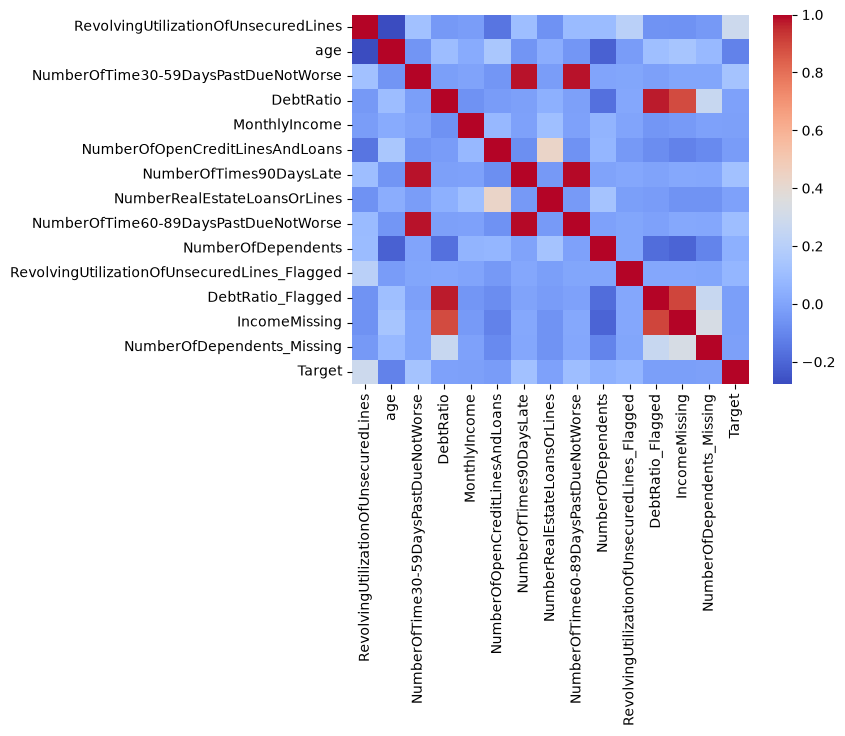

In [72]:
sns.heatmap(corr, cmap = "coolwarm")
#plt.colorbar()
plt.show()

No feature has a stronger linear correlation with the target. Late-payment columns shows a weak positive link, so I will use a model that can combine many weak signals.

**Checking out the relationship with the flagged column and target**

In [73]:
train.columns

Index(['RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents', 'RevolvingUtilizationOfUnsecuredLines_Flagged',
       'DebtRatio_Flagged', 'IncomeMissing', 'NumberOfDependents_Missing',
       'Target'],
      dtype='str')

In [74]:
flag = [c for c in train.columns if "Flag" in c or "Missing" in c]
flag

['RevolvingUtilizationOfUnsecuredLines_Flagged',
 'DebtRatio_Flagged',
 'IncomeMissing',
 'NumberOfDependents_Missing']

In [75]:
for c in flag:
    print(train.groupby(c)["Target"].agg(["mean", "size"]), "\n")

                                                  mean    size
RevolvingUtilizationOfUnsecuredLines_Flagged                  
0                                             0.065639  119167
1                                             0.313559     590 

                       mean   size
DebtRatio_Flagged                 
0                  0.069494  95907
1                  0.056268  23850 

                   mean   size
IncomeMissing                 
0              0.069289  96206
1              0.056940  23551 

                                mean    size
NumberOfDependents_Missing                  
0                           0.067417  116676
1                           0.045764    3081 



Revolving utilization flag is strongly linked to default (31% vs 6.6%). Debt ratio, income missing and dependents missing flags show only small gaps, so they are weak signals.

In [76]:
#Checking out the flagged debt ratio and missing income
pd.crosstab(train["DebtRatio_Flagged"], train["IncomeMissing"])

IncomeMissing,0,1
DebtRatio_Flagged,,
0,94250,1657
1,1956,21894


DebtRatio_Flagged and IncomeMissing overlap heavily (21,894 rows have both), so they carry almost the same information.

### Feature Engineering

In [77]:
#Identifying features with strongest cues to the target

#NumberOfTime30-59DaysPastDueNotWorse       
#NumberOfTimes90DaysLate                    
#NumberOfTime60-89DaysPastDueNotWorse


c30 = "NumberOfTime30-59DaysPastDueNotWorse"       
c90 = "NumberOfTimes90DaysLate"                    
c60 = "NumberOfTime60-89DaysPastDueNotWorse"


In [78]:
#Checking the max value of the 3 selected columns
for c in [c30, c60, c90]:
    print(c, X_train[c].value_counts().sort_index().tail().to_dict())

NumberOfTime30-59DaysPastDueNotWorse {10: 3, 11: 1, 12: 2, 96: 3, 98: 175}
NumberOfTime60-89DaysPastDueNotWorse {8: 2, 9: 1, 11: 1, 96: 3, 98: 175}
NumberOfTimes90DaysLate {14: 1, 15: 2, 17: 1, 96: 3, 98: 175}


In [79]:
#Checking if it the large values falls in all the 3 columns, same rows
codes= X_train[[c30, c60, c90]] >= 96
print(codes.sum())
print(codes.any(axis = 1).sum(), "rows have a code in an least one column")
print(codes.all(axis = 1).sum(), "rows have it in all three")


NumberOfTime30-59DaysPastDueNotWorse    178
NumberOfTime60-89DaysPastDueNotWorse    178
NumberOfTimes90DaysLate                 178
dtype: int64
178 rows have a code in an least one column
178 rows have it in all three


In [80]:
#Flagging this 3 columns and updating the values to missing values

for d in (X_train, X_test):
    d["late_code_flag"] = (d[[c30, c60, c90]] >= 96).any(axis = 1).astype(int)
    for c in [c30, c60, c90]:
        d.loc[d[c] >=96, c ] = np.nan

In [81]:
#Filling those missing values with thier median
for c in [c30, c60, c90]:
    fill = X_train[c].median()
    print(c, fill)
    X_train[c] = X_train[c].fillna(fill)
    X_test[c] = X_test[c].fillna(fill)


NumberOfTime30-59DaysPastDueNotWorse 0.0
NumberOfTime60-89DaysPastDueNotWorse 0.0
NumberOfTimes90DaysLate 0.0


In [82]:
#Checking the max value of the 3 selected columns
for c in [c30, c60, c90]:
    print(c, X_train[c].value_counts().sort_index().tail().to_dict())

NumberOfTime30-59DaysPastDueNotWorse {8.0: 17, 9.0: 10, 10.0: 3, 11.0: 1, 12.0: 2}
NumberOfTime60-89DaysPastDueNotWorse {6.0: 11, 7.0: 5, 8.0: 2, 9.0: 1, 11.0: 1}
NumberOfTimes90DaysLate {12.0: 1, 13.0: 3, 14.0: 1, 15.0: 2, 17.0: 1}


**Defining the new features**
- total_late: How many times the person was late, all added together
- any_late: 1 If ever late, 0 if never late
- serious_late: 1 if ever 90 days or more late, 0 if never

In [83]:
X_train["total_late"] = X_train[c30] + X_train[c60] + X_train[c90]
X_train["any_late"] = (X_train["total_late"] > 0).astype(int)
X_train["serious_late"] = (X_train[c90] > 0).astype(int)

In [84]:
#Checking out the new columns
X_train

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,RevolvingUtilizationOfUnsecuredLines_Flagged,DebtRatio_Flagged,IncomeMissing,NumberOfDependents_Missing,late_code_flag,total_late,any_late,serious_late
68020,0.861419,61,2.0,0.566166,12513.0,16,0.0,2,0.0,1.0,0,0,0,0,0,2.0,1,0
55223,0.966407,45,0.0,0.065950,3350.0,4,0.0,0,0.0,1.0,0,0,0,0,0,0.0,0,0
116777,0.907869,49,0.0,0.339884,11600.0,8,0.0,2,0.0,1.0,0,0,0,0,0,0.0,0,0
134150,0.062956,52,0.0,0.203208,9600.0,10,0.0,1,0.0,0.0,0,0,0,0,0,0.0,0,0
92804,0.248904,62,0.0,0.420186,8500.0,19,0.0,2,0.0,0.0,0,0,0,0,0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78899,0.003785,76,0.0,0.002204,8167.0,19,0.0,0,0.0,1.0,0,0,0,0,0,0.0,0,0
110200,0.203918,65,0.0,4.000000,5400.0,5,0.0,0,0.0,0.0,0,1,1,0,0,0.0,0,0
44514,0.010227,49,0.0,4.000000,5400.0,11,0.0,2,0.0,3.0,0,1,1,0,0,0.0,0,0
7461,0.169903,60,0.0,0.640853,10833.0,15,0.0,3,0.0,5.0,0,0,0,0,0,0.0,0,0


In [85]:
#Checking out the new columns
X_train[[c30, c60, c90, "total_late", "any_late", "serious_late"]].head(10)

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,total_late,any_late,serious_late
68020,2.0,0.0,0.0,2.0,1,0
55223,0.0,0.0,0.0,0.0,0,0
116777,0.0,0.0,0.0,0.0,0,0
134150,0.0,0.0,0.0,0.0,0,0
92804,0.0,0.0,0.0,0.0,0,0
85210,0.0,0.0,0.0,0.0,0,0
40405,0.0,0.0,0.0,0.0,0,0
103211,0.0,0.0,0.0,0.0,0,0
11620,1.0,0.0,0.0,1.0,1,0
3056,0.0,0.0,0.0,0.0,0,0


In [86]:
#Applying same for the X_test set

X_test["total_late"] = X_test[c30] + X_test[c60] + X_test[c90]
X_test["any_late"] = (X_test["total_late"] > 0).astype(int)
X_test["serious_late"] = (X_test[c90] > 0).astype(int)

In [87]:
X_test[[c30, c60, c90, "total_late", "any_late", "serious_late"]].sort_values(ascending = False, by = "total_late").head(10)

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,total_late,any_late,serious_late
143770,1.0,5.0,12.0,18.0,1,1
137310,3.0,1.0,13.0,17.0,1,1
89721,1.0,1.0,14.0,16.0,1,1
108197,5.0,5.0,5.0,15.0,1,1
41215,6.0,5.0,4.0,15.0,1,1
129684,10.0,2.0,3.0,15.0,1,1
61669,8.0,6.0,0.0,14.0,1,0
68019,8.0,2.0,4.0,14.0,1,1
29158,0.0,7.0,7.0,14.0,1,1
121149,2.0,1.0,11.0,14.0,1,1


In [88]:
#Checking if both the training and testing set have the same columns
print(X_train.columns.equals(X_test.columns))

True


**Feature Engineering: Late payment features**

In the EDA, three of the strongest columns against the target were
- NumberOfTime30-59DaysPastDueNotWorse
- NumberOfTime60-89DaysPastDueNotWorse
- NumberOfTimes90DaysLate

I built three new columns from them:
- total_late: all three counts added together
- any_late: 1 if the person was never late and 0 if the person was late at all
- serious_late: 1 if the person  was ever 90 days or more late, the worst kind

The new columns was built upon the training and the testing set to have the same features

### Scaling
- Using the Standard Scaler (It does well for logistic regression model)

In [89]:
#importing the library
from sklearn.preprocessing import StandardScaler

#initializing
SS = StandardScaler()

In [90]:
#fitting the scaler on just the training set

X_train_s = SS.fit_transform(X_train)
X_test_s = SS.transform(X_test)

### Training Model

- Logistic_Regression (base model)

In [91]:
#Importing the model

from sklearn.linear_model import LogisticRegression

In [92]:
#Initializing the Logistic Regression model

LR = LogisticRegression(class_weight = "balanced", max_iter = 1000)
LR

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [93]:
#Fitting the model on the training set

LR.fit(X_train_s, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [94]:
#predicting
y_pred = LR.predict(X_test_s)
proba = LR.predict_proba(X_test_s)[:, 1]

### Evaluation

In [95]:
#Using the precision_score, recall_score, f1_score
#Importing the metrics
from sklearn.metrics import precision_score, recall_score, f1_score

In [96]:
#Evaluating ...
print("Precision: ", round(precision_score(y_test, y_pred), 3))
print("Recall: ", round(recall_score(y_test, y_pred), 3))
print("F1: ", round(f1_score(y_test, y_pred), 3))

Precision:  0.216
Recall:  0.736
F1:  0.334


Baseline-LogisticRegression:

Precision 0.216, Recall 0.74, F1 0.334.
The model catches about 74% of defaulters, but only about 22% of it's flags are real defaulters, the expected trade with balanced class weights.

In [97]:
#Using the ROC-AUC score
#Importing the metric
from sklearn.metrics import roc_auc_score

In [98]:
#Evaluating ...
print("ROC-AUC: ", round(roc_auc_score(y_test, proba), 3))

ROC-AUC:  0.858


ROC-AUC = 0.858

It measures how well the model ranks real defaulters (1s) above non-defalters(0s), so 0.858 means the model puts most defaulters above most non-defaulters in its risk ranking

### Training Model
- Random Forest Classification

In [99]:
# Importing the model
from sklearn.ensemble import RandomForestClassifier

In [100]:
#Initializing
RFC = RandomForestClassifier(
    n_estimators= 200,
    max_depth = 10,
    min_samples_leaf= 20,
    class_weight = "balanced",
    n_jobs = 1,
    random_state= 42
)
RFC

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [101]:
#fitting the model on the actual training set (not scaled)

RFC.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [102]:
#Prediction ...
y_pred_rf = RFC.predict(X_test)
proba_rf = RFC.predict_proba(X_test)[:, 1]

### Evaluation

In [103]:
#Evaluating ...
print("Precision: ", round(precision_score(y_test, y_pred_rf), 3))
print("Recall: ", round(recall_score(y_test, y_pred_rf), 3))
print("F1: ", round(f1_score(y_test, y_pred_rf), 3))
print("ROC-AUC: ", round(roc_auc_score(y_test, proba_rf), 3))

Precision:  0.22
Recall:  0.753
F1:  0.341
ROC-AUC:  0.862


Random Forst scored cligghttly higher on all fout metrics (ROC-AUC 0.862 agains 0.858), So I chose it as the final model. The gap is small, so both models perform similarly on this data

In [105]:
#Columns that mattered the most
imp = pd.Series(RFC.feature_importances_, index = X_train.columns).sort_values(ascending = False)
print(imp.head(8))

RevolvingUtilizationOfUnsecuredLines    0.268660
total_late                              0.192762
any_late                                0.174557
NumberOfTimes90DaysLate                 0.065804
serious_late                            0.064664
NumberOfTime30-59DaysPastDueNotWorse    0.060398
age                                     0.042888
NumberOfTime60-89DaysPastDueNotWorse    0.029110
dtype: float64


In [107]:
#Saving the model
import joblib
joblib.dump(RFC, "randomforestmodel.joblib")

['randomforestmodel.joblib']

In [108]:
#model table
results = pd.DataFrame([
    {"Model": "LogisticRegression", "precision_score" : 0.216, "recall_score" : 0.736, "f1_score" : 0.334, "roc_auc_score" : 0.858},
    {"Model": "RandomForestClassifier", "precision_score" : 0.22, "recall_score" : 0.753, "f1_score" : 0.341, "roc_auc_score" : 0.862}
])
results

,Model,precision_score,recall_score,f1_score,roc_auc_score
0,LogisticRegression,0.216,0.736,0.334,0.858
1,RandomForestClassifier,0.220,0.753,0.341,0.862
